=== Estatísticas de Votos ===
count     128.000000
mean       36.851562
std       215.936346
min         1.000000
25%         1.000000
50%         2.000000
75%         7.000000
max      2033.000000
Name: qt_votos, dtype: float64

Limite para outlier: 16 votos
Quantidade de candidatos outliers: 15
           nm_urna_candidato  qt_votos
71             MÁRCIO FRANÇA      2033
96          CELSO RUSSOMANNO      1349
91          DELEGADO PALUMBO       277
62           ADRIANA RAMALHO       176
15  JUNTAS MULHERES SEM TETO       118
39           TAMIRES SAMPAIO        73
11             ANDRÉA WERNER        66
23               DRA ROBERTA        52
5               ANDRÉ SOARES        48
29             GRAÇA FERRARI        41


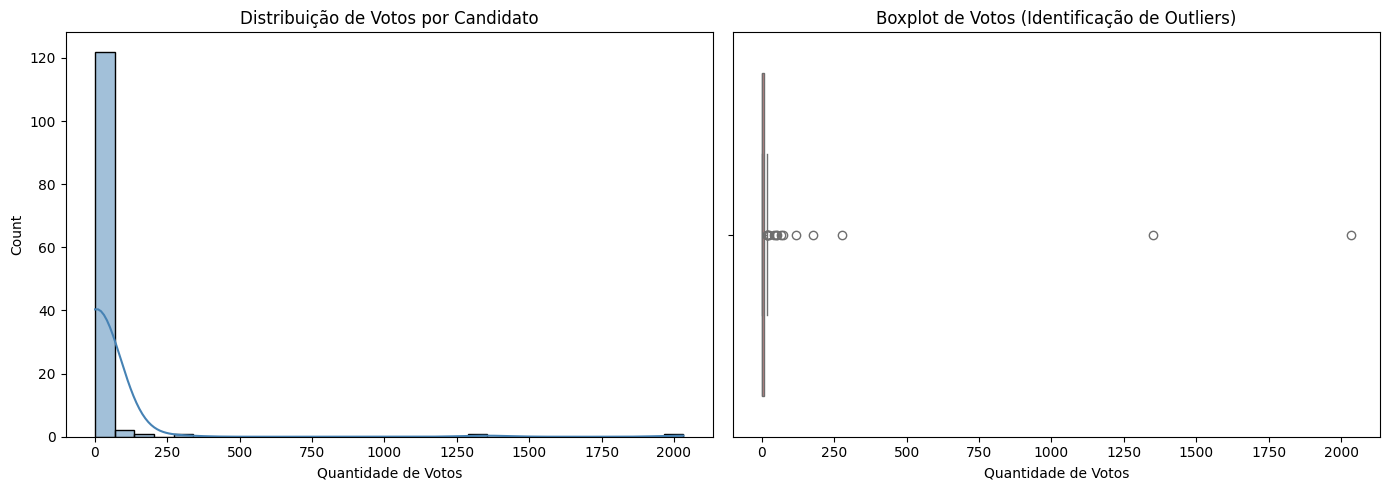

In [ ]:
# @title
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Carregar os dados utilizando o separador correto ';'
df_votos = pd.read_csv('fato_votos.csv', sep=';')
df_cand = pd.read_csv('dim_candidato.csv', sep=';')

# Unir votos por candidato (filtrando apenas votos válidos nominais, se aplicável)
votos_por_cand = df_votos.groupby('id_candidato')['qt_votos'].sum().reset_index()
df_analise = pd.merge(df_cand, votos_por_cand, on='id_candidato', how='inner')

# 2. Estatísticas descritivas (Média, Mediana, Desvio Padrão, Quartis)
print("=== Estatísticas de Votos ===")
print(df_analise['qt_votos'].describe())

# 3. Identificação de Outliers (Método IQR - Intervalo Interquartil)
Q1 = df_analise['qt_votos'].quantile(0.25)
Q3 = df_analise['qt_votos'].quantile(0.75)
IQR = Q3 - Q1
limite_superior = Q3 + 1.5 * IQR

outliers = df_analise[df_analise['qt_votos'] > limite_superior]
print(f"\nLimite para outlier: {limite_superior:.0f} votos")
print(f"Quantidade de candidatos outliers: {len(outliers)}")
print(outliers[['nm_urna_candidato', 'qt_votos']].sort_values(by='qt_votos', ascending=False).head(10))

# 4. Visualização da Distribuição e Outliers (Boxplot + Histograma)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df_analise['qt_votos'], bins=30, kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Distribuição de Votos por Candidato')
axes[0].set_xlabel('Quantidade de Votos')

sns.boxplot(x=df_analise['qt_votos'], ax=axes[1], color='lightcoral')
axes[1].set_title('Boxplot de Votos (Identificação de Outliers)')
axes[1].set_xlabel('Quantidade de Votos')

plt.tight_layout()
plt.show()